# 隠れ状態を差し替えて、答えを決めている層と位置を突き止める（アクティベーション・パッチング）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/09_lm_analysis/activation_patching.ipynb)

NLP クックブック 09-09 ／ 言語モデルの確率と内部を調べる

言語モデルが「フランスの首都は」に「パリ」と答えるとき、国名の情報がどの層のどの位置を通って答えに届くのかを、介入の実験で確かめたい。国名だけが違う 2 つの入力（きれいな入力と壊れた入力）を用意し、壊れた入力の実行のある層・ある位置の出力を、きれいな入力の実行の値に差し替えて、答えがどれだけ戻るかを層 × 位置のヒートマップにする。残差ストリーム（層の出力）全体のほか、アテンションと MLP の出力も分けて比べる。

In [1]:
!pip install -q matplotlib-fontja

In [2]:
import random
import numpy as np
import sentencepiece as spm
import torch
from huggingface_hub import hf_hub_download
from tokenizers import models
from transformers import AutoModelForCausalLM, AutoTokenizer

random.seed(0); np.random.seed(0); torch.manual_seed(0)

# SB Intuitions の Sarashina2.2-0.5B（指示チューニング前のベースモデル。MIT ライセンス）。この章のステアリングのレシピと同じモデル
name = "sbintuitions/sarashina2.2-0.5b"
tokenizer = AutoTokenizer.from_pretrained(name)
# transformers 5 系は、このモデルの SentencePiece (Unigram) を BPE に変換してしまい、学習時と違う分割になる。
# 元の tokenizer.model から語彙とスコアを読み、分割の方式だけを Unigram に戻す（特殊トークンやチャットテンプレートはそのまま）
sp = spm.SentencePieceProcessor(model_file=hf_hub_download(name, "tokenizer.model"))
tokenizer.backend_tokenizer.model = models.Unigram(
    [(sp.id_to_piece(i), sp.get_score(i)) for i in range(sp.get_piece_size())], unk_id=sp.unk_id(), byte_fallback=True)

# 0.5B のモデルの順伝播だけなので CPU でも動く（GPU があれば使う）。CPU でも使えるよう float32 で計算する
device = "cuda" if torch.cuda.is_available() else "cpu"
model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float32).to(device).eval()
n_layers = model.config.num_hidden_layers

# 国と首都（首都がどれも 1 トークンになるものを選んだ）。きれいな入力の国と、壊れた入力の国の組
capital = {"日本": "東京", "フランス": "パリ", "ドイツ": "ベルリン", "イタリア": "ローマ", "イギリス": "ロンドン", "中国": "北京",
           "韓国": "ソウル", "ロシア": "モスクワ", "スペイン": "マドリード", "タイ": "バンコク", "ギリシャ": "アテネ", "エジプト": "カイロ"}
pairs = [("フランス", "日本"), ("ドイツ", "イタリア"), ("イギリス", "中国"), ("ギリシャ", "エジプト")]
template = "{}の首都は？\nA: "

def encode(country):
    return tokenizer(tokenizer.bos_token + template.format(country), add_special_tokens=False, return_tensors="pt")["input_ids"].to(device)

def token_id(word):
    ids = tokenizer(word, add_special_tokens=False)["input_ids"]
    assert len(ids) == 1, (word, ids)                  # 国名も首都も 1 トークンのものだけを使う
    return ids[0]

ids = encode("フランス")
print([tokenizer.decode(i) for i in ids[0]])
SUBJ = 1                                               # 国名の位置（先頭の BOS の次）。どの国でもトークン数は同じ
with torch.no_grad():
    for clean, corrupt in pairs:
        assert encode(clean).shape == encode(corrupt).shape   # 2 つの入力のトークン数がそろっていること
        token_id(clean); token_id(corrupt)                    # 国名が 1 トークンであることを確かめる
        a, b = token_id(capital[clean]), token_id(capital[corrupt])
        lc = model(encode(clean)).logits[0, -1].float().log_softmax(-1)
        lx = model(encode(corrupt)).logits[0, -1].float().log_softmax(-1)
        # ロジットの差 = 対数確率の差: log P(きれいな入力の答え) − log P(壊れた入力の答え)
        print(f"{clean}→{capital[clean]} / {corrupt}→{capital[corrupt]}:  P(正解) {lc[a].exp():.2f} / {lx[b].exp():.2f}   "
              f"ロジットの差  きれい {lc[a] - lc[b]:+.2f}  壊れた {lx[a] - lx[b]:+.2f}")

['<s>', 'フランス', 'の首都', 'は', '？', '\n', 'A', ':', ' ']
フランス→パリ / 日本→東京:  P(正解) 0.88 / 0.60   ロジットの差  きれい +4.91  壊れた -5.93
ドイツ→ベルリン / イタリア→ローマ:  P(正解) 0.85 / 0.71   ロジットの差  きれい +5.80  壊れた -5.97
イギリス→ロンドン / 中国→北京:  P(正解) 0.90 / 0.80   ロジットの差  きれい +8.04  壊れた -7.44
ギリシャ→アテネ / エジプト→カイロ:  P(正解) 0.93 / 0.80   ロジットの差  きれい +7.45  壊れた -5.64


In [3]:
import contextlib
import time

@contextlib.contextmanager
def hooks(*module_and_fn):
    """with の中だけ forward hook を付ける（この章のステアリングのレシピと同じく、必ず外す）"""
    handles = [m.register_forward_hook(f) for m, f in module_and_fn]
    try:
        yield
    finally:
        for h in handles:
            h.remove()

KINDS = ["resid", "attn", "mlp"]
def module(kind, l):
    """層 l (1〜24) の、残差ストリームに書き込む部分。Llama 系の層は h = x + attn(norm(x)); 出力 = h + mlp(norm(h))"""
    layer = model.model.layers[l - 1]                  # この出力が hidden_states[l]（層 l）にあたる
    return {"resid": layer, "attn": layer.self_attn, "mlp": layer.mlp}[kind]

def get_h(out):                                        # transformers 5 では層と MLP の出力はテンソル、アテンションは（出力、重み）のタプル
    return out[0] if isinstance(out, tuple) else out
def put_h(out, h):
    return (h,) + tuple(out[1:]) if isinstance(out, tuple) else h

@torch.no_grad()
def run_with_cache(ids):
    """きれいな入力の実行で、全層の 3 種類の出力を保存する"""
    cache = {}
    def saver(key):
        def f(m, inputs, out):
            cache[key] = get_h(out)[0].detach().clone()
        return f
    with hooks(*[(module(k, l), saver((k, l))) for k in KINDS for l in range(1, n_layers + 1)]):
        model(ids)
    return cache

@torch.no_grad()
def patch_scan(ids, cache, kind, answers, positions, window=1, extra=()):
    """入力 ids の実行で、層 l・位置 p の kind の出力だけを cache の値に差し替えたときの、答えの対数確率（層、位置、答え）。
    位置ごとの差し替えを 1 つのバッチにまとめ、層ごとに 1 回の順伝播で計算する。
    window > 1 なら、層 l を中心とする連続した window 層をまとめて差し替える。extra は入力を壊すための追加の hook"""
    rows, pos = torch.arange(len(positions)), torch.tensor(positions)
    batch = ids.repeat(len(positions), 1)
    def patcher(l):
        clean = cache[kind, l][pos]
        def patch(m, inputs, out):
            h = get_h(out).clone()
            h[rows, pos] = clean                       # バッチの i 番目は、位置 positions[i] だけを差し替える
            return put_h(out, h)
        return patch
    result = []
    for l in range(1, n_layers + 1):
        layers = range(max(1, l - window // 2), min(n_layers, l + (window - 1) // 2) + 1)
        with hooks(*[(module(kind, lw), patcher(lw)) for lw in layers], *extra):
            # 最後の位置のロジットだけを計算する（出力層は語彙が約 10 万と大きく、全位置で計算すると重い）
            result.append(model(batch, logits_to_keep=1).logits[:, -1].float().log_softmax(-1)[:, answers])
    return torch.stack(result)

# 国名より前の位置 (BOS) はどちらの入力でも同じなので、国名の位置から最後までを調べる
positions = list(range(SUBJ, ids.shape[1]))
labels = ["（国名）" if p == SUBJ else tokenizer.decode(ids[0, p]).replace("\n", "\\n").replace(" ", "_") for p in positions]
labels[-1] += "（最後）"                                # 最後の位置は空白のトークン（図では「_」）
recovery, lds = {k: [] for k in KINDS}, []
t0 = time.time()
for clean, corrupt in pairs:                           # Colab の CPU で 5〜8 分ほど（目安）
    a, b = token_id(capital[clean]), token_id(capital[corrupt])
    cache = run_with_cache(encode(clean))
    with torch.no_grad():
        lc = model(encode(clean)).logits[0, -1].float().log_softmax(-1)
        lx = model(encode(corrupt)).logits[0, -1].float().log_softmax(-1)
    ld_clean, ld_corrupt = (lc[a] - lc[b]).item(), (lx[a] - lx[b]).item()
    lds.append((ld_clean, ld_corrupt))
    for k in KINDS:
        lp = patch_scan(encode(corrupt), cache, k, [a, b], positions)
        ld = (lp[..., 0] - lp[..., 1]).cpu().numpy()
        # 戻った割合: 0 = 壊れた入力のまま、1 = きれいな入力と同じロジットの差
        recovery[k].append((ld - ld_corrupt) / (ld_clean - ld_corrupt))
recovery = {k: np.stack(v) for k, v in recovery.items()}   # （組、層、位置）
print(f"{time.time() - t0:.0f} 秒", {k: v.shape for k, v in recovery.items()})

5 秒 {'resid': (4, 24, 8), 'attn': (4, 24, 8), 'mlp': (4, 24, 8)}


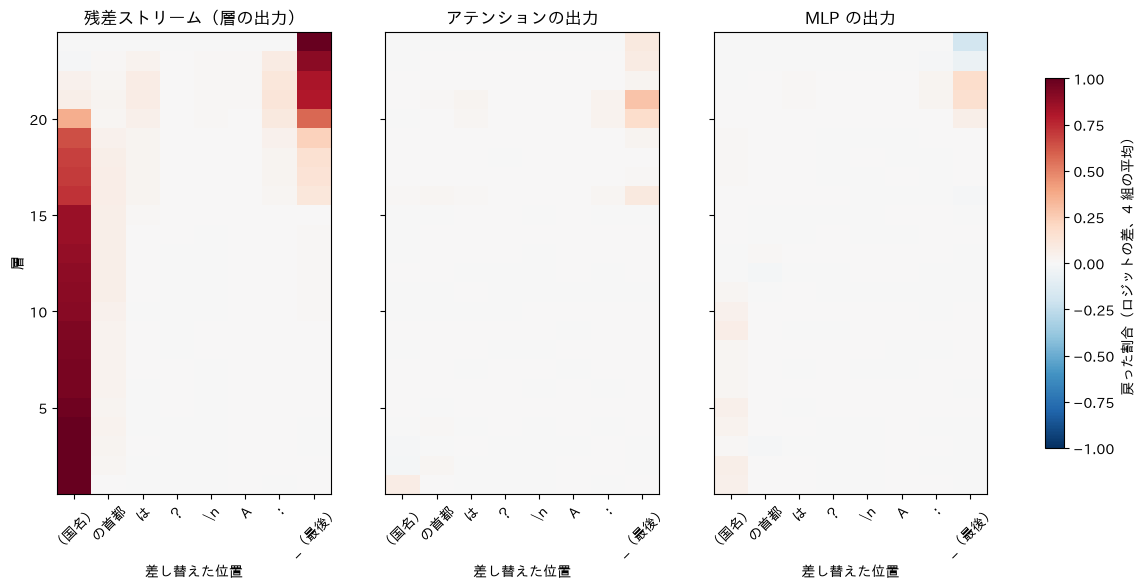

残差ストリーム（層の出力）    最大 1.00（層 24、位置 _（最後））  国名の位置の最大 1.00（層 3）  最後の位置の最大 1.00（層 24）
アテンションの出力        最大 0.28（層 21、位置 _（最後））  国名の位置の最大 0.07（層 1）  最後の位置の最大 0.28（層 21）
MLP の出力          最大 0.18（層 22、位置 _（最後））  国名の位置の最大 0.06（層 9）  最後の位置の最大 0.18（層 22）
残差ストリーム  国名の位置: 1.00 1.00 1.00 1.00 0.97 0.95 0.95 0.94 0.93 0.91 0.90 0.89 0.88 0.86 0.86 0.72 0.70 0.68 0.64 0.36 0.06 0.04 -0.01 -0.00
残差ストリーム  最後の位置: 0.00 0.00 -0.00 -0.00 0.00 0.00 0.00 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.00 0.12 0.14 0.15 0.23 0.57 0.80 0.81 0.91 1.00
組ごとの最小〜最大（国名の位置、層 1, 6, 12, 18）: [(0.99, 1.01), (0.87, 0.99), (0.68, 0.99), (0.37, 0.91)]
logit lens フランス→パリ: 初めて 1 位になる層 21  順位（層 12, 16, 18, 20, 22, 24）: [11150, 1928, 708, 4, 1, 1]
logit lens ドイツ→ベルリン: 初めて 1 位になる層 21  順位（層 12, 16, 18, 20, 22, 24）: [22637, 4553, 1545, 2, 1, 1]
logit lens イギリス→ロンドン: 初めて 1 位になる層 20  順位（層 12, 16, 18, 20, 22, 24）: [1719, 424, 148, 1, 1, 1]
logit lens ギリシャ→アテネ: 初めて 1 位になる層 21  順位（層 12, 16, 18, 20, 22, 24）: [50291, 15817, 1248, 5, 1, 1]


In [4]:
import matplotlib.pyplot as plt
import matplotlib_fontja  # import するだけで日本語のフォントが使える

titles = {"resid": "残差ストリーム（層の出力）", "attn": "アテンションの出力", "mlp": "MLP の出力"}
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
for ax, k in zip(axes, KINDS):
    m = recovery[k].mean(0)
    im = ax.imshow(m, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto", origin="lower",
                   extent=(-0.5, len(positions) - 0.5, 0.5, n_layers + 0.5))
    ax.set_xticks(range(len(positions)), labels, rotation=45)
    ax.set_title(titles[k]); ax.set_xlabel("差し替えた位置")
axes[0].set_ylabel("層")
fig.colorbar(im, ax=axes, label=f"戻った割合（ロジットの差、{len(pairs)} 組の平均）", shrink=0.8)
plt.show()

for k in KINDS:
    m = recovery[k].mean(0)
    l, j = np.unravel_index(np.argmax(m), m.shape)
    print(f"{titles[k]:16} 最大 {m[l, j]:.2f}（層 {l + 1}、位置 {labels[j]}）  "
          f"国名の位置の最大 {m[:, 0].max():.2f}（層 {np.argmax(m[:, 0]) + 1}）  最後の位置の最大 {m[:, -1].max():.2f}（層 {np.argmax(m[:, -1]) + 1}）")
# 残差ストリームで、国名の位置と最後の位置のどちらを差し替えると戻るかが、何層目で入れ替わるか
r = recovery["resid"]
print("残差ストリーム  国名の位置:", " ".join(f"{x:.2f}" for x in r[:, :, 0].mean(0)))
print("残差ストリーム  最後の位置:", " ".join(f"{x:.2f}" for x in r[:, :, -1].mean(0)))
print("組ごとの最小〜最大（国名の位置、層 1, 6, 12, 18）:", [(round(float(r[:, l - 1, 0].min()), 2), round(float(r[:, l - 1, 0].max()), 2)) for l in [1, 6, 12, 18]])

# 比較: 同じプロンプトの logit lens（この章の logit lens のレシピと同じく、各層の隠れ状態を最終層の正規化と出力層に通す）。
# 最後の位置で、きれいな入力の正解が初めて 1 位になる層
with torch.no_grad():
    for clean, _ in pairs:
        a = token_id(capital[clean])
        out = model(encode(clean), output_hidden_states=True)
        hs = torch.stack(out.hidden_states[1:-1])[:, 0, -1]   # 層 1〜23 の最後の位置。最後の要素（層 24）は正規化済みなので除く
        lens = torch.cat([model.lm_head(model.model.norm(hs)), out.logits[0, -1:]]).float()   # 層 24 はモデル本来の出力
        rank = (lens > lens[:, [a]]).sum(-1).add(1).cpu().numpy()                             # 正解の順位（1 = 1 位）
        print(f"logit lens {clean}→{capital[clean]}: 初めて 1 位になる層 {int(np.argmax(rank == 1)) + 1}  "
              f"順位（層 12, 16, 18, 20, 22, 24）: {rank[[11, 15, 17, 19, 21, 23]].tolist()}")

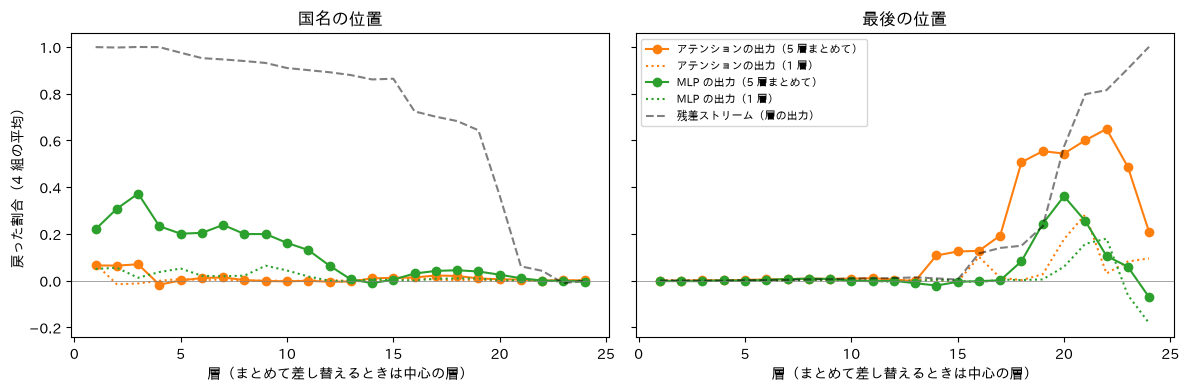

アテンションの出力 5 層・国名の位置: 最大 0.07（層 3 が中心）  0.06 0.06 0.07 -0.02 0.00 0.01 0.01 0.00 -0.00 -0.00 -0.00 -0.01 -0.00 0.01 0.01 0.01 0.02 0.02 0.01 0.01 0.00 -0.00 0.00 0.00
アテンションの出力 5 層・最後の位置: 最大 0.65（層 22 が中心）  -0.00 -0.00 0.00 0.00 0.00 0.01 0.01 0.01 0.01 0.01 0.01 0.00 -0.00 0.11 0.12 0.13 0.19 0.51 0.55 0.54 0.60 0.65 0.49 0.21
MLP の出力 5 層・国名の位置: 最大 0.37（層 3 が中心）  0.22 0.31 0.37 0.23 0.20 0.20 0.24 0.20 0.20 0.16 0.13 0.06 0.01 -0.01 0.00 0.03 0.04 0.04 0.04 0.03 0.01 0.00 -0.00 -0.00
MLP の出力 5 層・最後の位置: 最大 0.36（層 20 が中心）  -0.00 -0.00 -0.00 0.00 -0.00 0.00 0.01 0.01 0.01 -0.00 -0.00 -0.00 -0.01 -0.02 -0.01 -0.00 0.00 0.08 0.24 0.36 0.25 0.11 0.06 -0.07


In [5]:
# 1 層だけの MLP やアテンションでは戻る割合が小さい。ROME と同じく、連続した数層（ここでは 5 層）をまとめて差し替える
# 端の層（層 1〜2 と 23〜24 が中心のとき）は窓が切れて 3〜4 層になる。国名の位置と最後の位置だけを調べる（Colab の CPU で 2〜3 分ほど）
W = 5
window = {k: [] for k in ["attn", "mlp"]}
for (clean, corrupt), (ld_clean, ld_corrupt) in zip(pairs, lds):
    a, b = token_id(capital[clean]), token_id(capital[corrupt])
    cache = run_with_cache(encode(clean))
    for k in window:
        lp = patch_scan(encode(corrupt), cache, k, [a, b], [SUBJ, positions[-1]], window=W)
        window[k].append(((lp[..., 0] - lp[..., 1]).cpu().numpy() - ld_corrupt) / (ld_clean - ld_corrupt))
window = {k: np.stack(v) for k, v in window.items()}   # （組、層、位置 2 つ）

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
layers = np.arange(1, n_layers + 1)
for ax, j, jj, t in [(axes[0], 0, 0, "国名の位置"), (axes[1], 1, -1, "最後の位置")]:
    for k, c in [("attn", "tab:orange"), ("mlp", "tab:green")]:
        ax.plot(layers, window[k][:, :, j].mean(0), "o-", color=c, label=f"{titles[k]}（{W} 層まとめて）")
        ax.plot(layers, recovery[k][:, :, jj].mean(0), ":", color=c, label=f"{titles[k]}（1 層）")
    ax.plot(layers, recovery["resid"][:, :, jj].mean(0), "k--", alpha=0.5, label=titles["resid"])
    ax.axhline(0, color="gray", lw=0.5); ax.set_title(t); ax.set_xlabel("層（まとめて差し替えるときは中心の層）")
axes[0].set_ylabel(f"戻った割合（{len(pairs)} 組の平均）"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
for k in window:
    for j, t in [(0, "国名の位置"), (1, "最後の位置")]:
        m = window[k][:, :, j].mean(0)
        print(f"{titles[k]} {W} 層・{t}: 最大 {m.max():.2f}（層 {m.argmax() + 1} が中心）  " + " ".join(f"{x:.2f}" for x in m))

フランス: P(パリ) きれい 0.88 → ノイズ 0.06
ドイツ: P(ベルリン) きれい 0.85 → ノイズ 0.02
イギリス: P(ロンドン) きれい 0.90 → ノイズ 0.07
ギリシャ: P(アテネ) きれい 0.93 → ノイズ 0.01


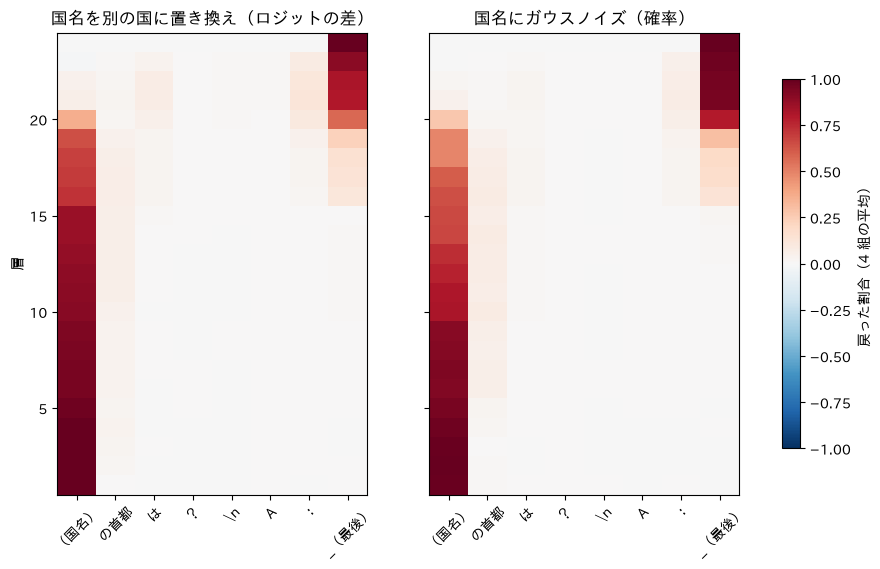

ノイズ  国名の位置: 0.99 1.00 0.98 0.98 0.95 0.92 0.93 0.92 0.91 0.81 0.81 0.77 0.74 0.67 0.66 0.64 0.60 0.49 0.49 0.27 0.04 0.02 -0.00 -0.00
ノイズ  最後の位置: -0.00 -0.00 -0.00 0.00 -0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.01 0.01 0.01 0.02 0.13 0.18 0.19 0.30 0.79 0.95 0.95 0.97 1.00


In [6]:
# 比較: ROME の causal tracing と同じく、国名の埋め込みにガウスノイズを足して壊し、そこへきれいな残差ストリームを戻す
# ノイズの標準偏差は、埋め込みの標準偏差の 3 倍（ROME は文章のトークンの埋め込みから測る。ここでは 12 か国の入力のトークンで測る）。Colab の CPU で 2〜3 分ほど
with torch.no_grad():
    emb = model.model.embed_tokens(torch.cat([encode(c)[0] for c in capital]))
nu = 3 * emb.std().item()
rec_noise = []
for i, (clean, _) in enumerate(pairs):
    a = token_id(capital[clean])
    noise = torch.randn(model.config.hidden_size, generator=torch.Generator().manual_seed(i)).to(device) * nu
    def add_noise(m, inputs, out):
        out = out.clone(); out[:, SUBJ] += noise; return out   # バッチのどの行にも同じノイズを足す
    corrupt_hook = (model.model.embed_tokens, add_noise)
    cache = run_with_cache(encode(clean))
    with torch.no_grad(), hooks(corrupt_hook):
        p_noise = model(encode(clean)).logits[0, -1].float().softmax(-1)[a].item()
    with torch.no_grad():
        p_clean = model(encode(clean)).logits[0, -1].float().softmax(-1)[a].item()
    p = patch_scan(encode(clean), cache, "resid", [a], positions, extra=[corrupt_hook])[..., 0].exp().cpu().numpy()
    rec_noise.append((p - p_noise) / (p_clean - p_noise))   # ROME の指標は確率。ここでは戻った割合にそろえる
    print(f"{clean}: P({capital[clean]}) きれい {p_clean:.2f} → ノイズ {p_noise:.2f}")
rec_noise = np.stack(rec_noise)

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, (m, t) in zip(axes, [(recovery["resid"].mean(0), "国名を別の国に置き換え（ロジットの差）"), (rec_noise.mean(0), "国名にガウスノイズ（確率）")]):
    im = ax.imshow(m, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto", origin="lower", extent=(-0.5, len(positions) - 0.5, 0.5, n_layers + 0.5))
    ax.set_xticks(range(len(positions)), labels, rotation=45); ax.set_title(t)
axes[0].set_ylabel("層"); fig.colorbar(im, ax=axes, label=f"戻った割合（{len(pairs)} 組の平均）", shrink=0.8)
plt.show()
print("ノイズ  国名の位置:", " ".join(f"{x:.2f}" for x in rec_noise[:, :, 0].mean(0)))
print("ノイズ  最後の位置:", " ".join(f"{x:.2f}" for x in rec_noise[:, :, -1].mean(0)))

- アクティベーション・パッチング (activation patching) は、2 つの入力の実行の間で内部の値を差し替え、出力の変化からその値の役割を調べる介入の実験である。Meng ら (NeurIPS 2022) の ROME の causal tracing は、GPT-2 XL で主語の埋め込みにガウスノイズ（埋め込みの標準偏差の 3 倍、10 回）を足して壊し、きれいな実行の隠れ状態を 1 か所ずつ戻して正解の確率の回復を測った（考え方は Vig ら (2020) の因果媒介分析による）。ここでは、ノイズの代わりに国名を別の国に置き換えて壊し、指標をロジットの差にした。Zhang & Nanda (ICLR 2024) は、入力の分布から外れにくいこの置き換え (symmetric token replacement) と、ロジットの差を勧めている。
- この実行（4 組の平均）では、残差ストリームを国名の位置で戻すと、層 15 までは 0.86 以上戻ったが、層 16 で 0.72、層 20 で 0.36 に下がり、層 21 以降はほぼ 0 だった。逆に最後の位置で戻すと、層 15 まではほぼ 0 で、層 16 で 0.12、層 20 で 0.57、層 21 で 0.80 になった。国名の情報は層 16〜21 のあたりで国名の位置から最後の位置へ移り、間の「の首都」「は」などの位置はほとんど通らない。ただし層 18 の国名の位置の値は組によって 0.37〜0.91 と違い、移る層は組ごとにずれる。組は 4 つだけなので、層の 1〜2 個の違いは言えない。
- 1 層だけの差し替えでは、アテンションの出力の最大は 0.28（層 21、最後の位置）、MLP の出力は 0.18（層 22、最後の位置）と小さい。ROME と同じく連続した層（ここでは 5 層）をまとめて戻すと、最後の位置のアテンションは層 18〜22 を中心にしたときに 0.51〜0.65 戻った。最後の位置の MLP も層 19〜21 を中心にしたときに 0.24〜0.36 戻るが、アテンションのほうが大きく、国名の情報を最後の位置へ運んでいるのは主にアテンションだと示唆される（ROME の「後ろの層の最後の位置のアテンション」に対応する）。国名の位置の MLP は層 1〜10 を中心にしたときに 0.16〜0.37 戻り、層 13 以降はほぼ 0 だった。ROME が主語の最後のトークンの中間層の MLP に見つけた「早い場所」に似ているが、ここでは前半の層に出た。まとめて差し替えた結果は窓の中の層の合計の効果で、局所化を大きく見せやすい (Zhang & Nanda) ので、1 層の結果と合わせて見る。
- ROME と同じガウスノイズで壊すと、正解の確率は 0.85〜0.93 から 0.01〜0.07 に下がり、戻したときの図は置き換えの場合とおおむね同じ形になった。ただし国名の位置の値は層 10 で 0.81、層 18 で 0.49 と早めに下がり、最後の位置は層 20 で 0.79 まで戻った（置き換えでは 0.91、0.68、0.57）。壊し方と指標（確率とロジットの差）の両方が違うので、どちらの効果かはこの比較では分けられない。Heimersheim & Nanda (2024) は、確率は飽和しやすく図を実際より鋭く見せるとして、ロジットの差（対数確率の差）を最も信頼すると書いている。ここではノイズを組ごとに 1 回しか引いておらず、標準偏差も 12 か国の入力のトークンの埋め込みから測った。
- この章の「BERT の各層に品詞や構文の情報がどれくらい入っているかを調べる（プロービング）」と「言語モデルのどの層で次のトークンの予測が固まるかを見る（logit lens と tuned lens）」は、その層から情報が読み出せることを示すだけだった。パッチングは、その位置の値を差し替えると答えが変わることを示す介入の実験で、情報がどこを通って答えに使われるかが分かる。同じプロンプトで logit lens を見ると（ヒートマップのセルの後半）、最後の位置で正解が初めて 1 位になるのは層 20〜21 で、層 18 ではまだ 148〜1,248 位だった。最後の位置を差し替えると層 16 から答えが戻り始める（層 16 で 0.12、層 19 で 0.23）ので、国名の情報は、logit lens で答えが読み出せるようになる少し前から最後の位置に届き始めている。hook の付け外しはこの章の「隠れ状態にベクトルを足して生成の感情や文体を変える（アクティベーション・ステアリング）」と同じで、ステアリングが決まった方向のベクトルをすべての位置に足すのに対し、パッチングは 1 つの位置の値を別の入力の実行の値と丸ごと入れ替える。
- ここで調べたのは、壊れた実行にきれいな値を戻す向き（Heimersheim & Nanda の denoising）で、その値だけで答えを戻せるか（十分性）を見ている。逆にきれいな実行に壊れた値を入れる向き (noising) は、その値が欠かせないか（必要性）を見るもので、結果は一致するとは限らない。複数の部品がそろって初めて働く場合は、1 か所を戻しても答えは戻らない。置き換えで壊すには 2 つの入力のトークン数と位置がそろっている必要があり、ここでは国名も首都も 1 トークンのものだけを選んだ（そろわない場合はノイズで壊す）。大きなモデルで多くの部品を調べるなら、この章の logit lens のレシピで紹介した nnsight などのライブラリが使える。
- モデルは SB Intuitions の Sarashina2.2-0.5B（MIT ライセンス）、プロンプトと国の組は自作。トークナイザーの修正は、大規模言語モデルの章の「オープンな LLM とチャットする（チャットテンプレート）」の注意書きを参照。この実行は GPU で float32 を使い、パッチングのセルが 5 秒だった。GPU なしの Colab CPU でも動き、2 スレッドの CPU（ハイパースレッディングの 1 コア）で試したときは全体が約 8 分半、パッチングのセルが約 5 分だった。出力層は語彙が大きいので、`logits_to_keep=1` で最後の位置だけ計算して速くしている。